# Tres respuestas para un chancador: la simulación de partículas, el balance poblacional con un modelo de capacidad de mandíbulas y la medición, en las tres alimentaciones de los ensayos de laboratorio

**Pregunta:** En las tres alimentaciones medidas, ¿cuál está más cerca de la medición, la simulación de partículas o el balance poblacional con un modelo de capacidad de mandíbulas, y por qué?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 01 y 02 de este tema; los temas 03 y 04 para el balance poblacional y el modelo de capacidad
- **Tiempo de lectura:** unos 100 minutos (el lote en vivo toma cerca de medio minuto)

## Objetivos

Al terminar este notebook puedes:

- calcular a mano la capacidad de un chancador de mandíbulas con las ecuaciones de Sastri (1994) y contrastar el resultado con el módulo de chancador de laboratorio del producto, y decir qué supone la clasificación del balance poblacional y qué rango publicado la acota;
- seguir el cálculo de Whiten del módulo del producto en una alimentación, y convertir la energía medida por tonelada en el índice de trabajo que necesitaría la ley de Bond;
- leer el documento versionado de los tres lados en las tres alimentaciones, campo por campo: qué guarda un lado, qué guarda un veredicto, qué dicen su banda y su fundamento y cuándo un veredicto está resuelto;
- decir, con números, qué lado está más cerca de la medición en cada alimentación y cada magnitud, qué veredictos se cumplen y cuáles no, y qué respaldan el documento, el registro del paquete y las fuentes citadas como razón de las diferencias;
- decir dónde se quiebra la comparación, en las corridas que no se completaron y en la sensibilidad del balance poblacional a sus tres parámetros de clasificación, y correr el mismo módulo en otro chancador.

## Preparación

El entorno es el de los notebooks 01 y 02: el paquete publicado `crushdem` 0.6.0 con sus núcleos compilados, que corre el lote en vivo y entrega el protocolo de comparación, y el módulo de chancador de laboratorio del producto, importado por ruta desde el pipeline.

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

La celda imprime las versiones e importa, además del caso y el protocolo del paquete, el módulo `labjaw` con el modelo de capacidad y la evaluación de una alimentación estrecha, el término de Bond, la curva de clasificación y la regla de carpeta de la etapa.

In [1]:
# Imprime las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import collections
import contextlib
import importlib.metadata as md
import io
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas: el notebook no define ningún método propio
from crushdem import comparison
from crushdem.breakage import median_fracture_energy
from crushdem.cases import barrios2020 as case
from pipeline.dem import points as P
from pipeline.model.crusher import labjaw
from pipeline.model.crusher.breakage import BETA, GAMMA, specific_energy, t10_of
from pipeline.model.crusher.capacity import bond_power
from pipeline.model.crusher.classification import classify
from pipeline.stages import dem as stage
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Las mediciones son las de Barrios, Jimenez-Herrera, Fuentes-Torres y Tavares (2020), https://doi.org/10.3390/min10080717, CC BY 4,0, como las describe el notebook 01. Los tres lados están en un archivo de este repositorio, `data/derived/dem/jaw-lab.json`, el documento de la fila `dem-run` del catálogo (esquema `docs/contracts/schemas/dem-run.schema.json`, versión 1.0.0), calculado por `data-pipeline/run.py dem` con `crushdem` 0.6.0: para cada uno de los tres puntos de operación (las alimentaciones 63/52, 31,5/26,5 y 16/13,2 mm a 6,0 Hz y un lado cerrado de 7,5 mm) guarda `measured`, `simulation` (la corrida de tamaño completo de 6 kg), `population_balance` (el módulo de chancador de laboratorio) y `verdicts`. Un veredicto compara dos lados de un punto en una magnitud con una banda fijada antes de toda corrida: caudal dentro de 10 por ciento, potencia neta dentro de 30 por ciento y razón de reducción, el F80 de la alimentación sobre el P80 del producto, dentro de 15 por ciento.

La celda lee el documento e imprime su estado, las bandas y las claves de un punto.

In [2]:
# El documento versionado del cálculo: los tres lados en los tres puntos de operación, y su estado
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
points = {p["feed_class"]: p for p in doc["points"]}
feeds = list(points)
bands = doc["bands"]
print("estado:", doc["state"], "| corridas incompletas:", doc["incomplete"], "| schema:", doc["schema"])
print("bandas fijadas antes de las corridas (caudal, potencia neta, razón de reducción):",
      bands["throughput_relative"], bands["net_power_relative"], bands["reduction_ratio_relative"])
print("claves de un punto:", list(points["63/52"]))
print("claves de sus veredictos:", list(points["63/52"]["verdicts"]))

estado: partial | corridas incompletas: ['31.5-26.5'] | schema: chancadem.dem.run/v1
bandas fijadas antes de las corridas (caudal, potencia neta, razón de reducción): 0.1 0.3 0.15
claves de un punto: ['id', 'feed_class', 'feed_mm', 'feed_mean_mm', 'feed_f80_mm', 'measured', 'paper_simulation', 'simulation', 'population_balance', 'verdicts']
claves de sus veredictos: ['simulation_vs_measured', 'population_balance_vs_measured', 'population_balance_vs_simulation']


El estado del documento es `partial`: una de las tres corridas de partículas no se completó, e `incomplete` la nombra, la alimentación 31,5/26,5 mm (el id de su punto escribe la alimentación con un guion). Todos los demás campos están presentes, así que el documento se lee tal como es y nada en este notebook rellena un valor que el documento deja vacío. La celda siguiente imprime un veredicto como lo escribe el documento, para el caudal de la simulación de partículas en la alimentación gruesa.

In [3]:
# Un veredicto como lo escribe el documento, para el caudal de la simulación de partículas de la alimentación gruesa
verdict = points["63/52"]["verdicts"]["simulation_vs_measured"]["throughput"]
for key, value in verdict.items():
    shown = round(value, 4) if isinstance(value, float) else value
    print(f"{key:>16s}: {shown}")

           first: 2167.06
          second: 798.662
  relative_error: 1.7134
            band: 0.1
         verdict: not met
           basis: None
        resolved: True
edge_distance_se: 25.5701


Los campos se leen así. `first` es el valor del primer lado del par, aquí el caudal simulado de 2167,06 kg/h, y `second` el del segundo, los 798,662 kg/h medidos. El `relative_error` es $(first - second)/second$, +1,7134, es decir +171 por ciento. La `band` es 0,1, así que el veredicto es `not met` (el error absoluto excede la banda). `basis` está vacío cuando un número decidió el veredicto y nombra la razón cuando ninguno pudo (`run_incomplete`, `no_work_index`, `nothing_passed`, `no_window`). `resolved` dice si la dispersión de los golpes puede explicar la diferencia: es verdadero cuando el borde de banda más cercano queda a más de dos errores estándar de la media de la ventana, y aquí queda a 25,5701 errores estándar (`edge_distance_se`), así que el desacierto no es ruido de una ventana. `resolved` existe solo para los veredictos que descansan en una estadística de ventana, los dos que comparan la simulación con la medición, y está vacío en todos los demás. El documento también guarda, solo en la alimentación gruesa, `paper_simulation`: la potencia neta y el caudal simulados por el propio artículo fuente, con la cadena de fuente de cada uno; es contexto para el lector y no entra en ningún veredicto.

## Método

Tres lados responden la misma pregunta en cada punto. La medición es la del artículo. La simulación de partículas es el método de elementos discretos con reemplazo de partículas de Cleary y Sinnott (2015) y Barrios et al. (2020) tal como lo implementa `crushdem` 0.6.0, cuyos pasos desarma el notebook 02. No es la simulación propia del artículo: rompe esferas con el modelo de energía de Tavares (2022) y una roca derivada de los ensayos de una partícula del artículo, donde el artículo usó una fuerza umbral y un conjunto fijo de hijas, ajustado a su propio ensayo de chancado con la alimentación distribuida (página 7), de modo que su progenie se calibró con el producto de la misma máquina mientras los parámetros del paquete vienen de ensayos de una partícula y de una roca de la literatura, y corre con el contacto de la Tabla 3 del artículo. El resultado propio del artículo se pone junto a la medición en la comparación. El balance poblacional es el motor del producto, el modelo de Whiten del tema 03, especializado al chancador de laboratorio por un módulo que guarda el modelo de capacidad de mandíbulas de Sastri (1994), una primera estimación de clasificación con rangos de la literatura y un vínculo con la roca. Nada de ese módulo se ajusta a una medición del chancador de laboratorio: una prueba del producto lee su fuente en busca de valores medidos y no encuentra ninguno. Los pasos siguientes lo corren a mano y con el módulo, y luego la simulación de partículas.

### Paso 1: el modelo de capacidad de mandíbulas

Sastri (1994) reelabora los datos de laboratorio de Hersam en una capacidad volumétrica. Con $G$ la abertura de alimentación, $S$ el ajuste de lado cerrado, $T$ la carrera, $w$ el ancho, $N$ los golpes por minuto y $D$ la profundidad entre las mandíbulas, todas las longitudes en metros,

$$D = 3.25\,G^{1.15}, \qquad N_c = 66.4\left[\frac{G-(S+T)}{D\,T}\right]^{1/2}, \qquad V_h = 60\,N\,w\left(S+\frac{T}{2}\right)a, \qquad a = \frac{D\,T}{G-(S+T)}\ \ (N<N_c),$$

donde $N_c$ es la velocidad crítica y $a$ la altura del prisma de roca que cae por golpe bajo ella; sobre $N_c$ el prisma es $a = 450\,g/N^2$. La capacidad en t/h es

$$W = V_h\,K_1K_2K_3\,d, \qquad K_1 = 0.85 - \left(\frac{F_{av}}{G}\right)^{2.5}, \qquad K_2 = 1.92\times 10^{-6.5\,T/G},$$

con $d$ la densidad en t/m$^3$, $F_{av}$ la media de los límites de la clase de alimentación y $K_3 = 1.0$ para roca dura (estos $K$ son los factores de capacidad de Sastri, no los parámetros de clasificación del paso siguiente). La celda calcula cada término para la alimentación 63/52 mm a mano y llama al módulo.

In [4]:
# Paso 1: la capacidad de Sastri del chancador para la alimentación 63/52 mm, término a término a mano, frente al
# módulo del producto
jaw = labjaw.OTSUKA_BARRIOS_2020
gape, width, css, throw = jaw.gape_mm / 1000, jaw.width_mm / 1000, P.CSS_MM / 1000, P.THROW_MM / 1000
speed, density = P.SPEED_RPM, jaw.density_t_m3
f_av = labjaw.class_mean_mm(52.0, 63.0) / 1000
depth = 3.25 * gape**1.15
n_crit = 66.4 * math.sqrt((gape - (css + throw)) / (depth * throw))
prism = depth * throw / (gape - (css + throw))
vh = 60.0 * speed * width * (css + throw / 2.0) * prism
k1 = 0.85 - (f_av / gape) ** 2.5
k2 = 1.92 * 10.0 ** (-6.5 * throw / gape)
by_hand = vh * k1 * k2 * jaw.material_k3 * density * 1000.0
cap = labjaw.jaw_capacity_tph(speed, width, css, throw, gape, f_av, density, jaw.material_k3)
print(f"D = {depth:.4f} m, Nc = {n_crit:.1f} rpm frente a N = {speed:.0f} rpm (rama {cap.branch}), a = {prism:.4f} m")
print(f"Vh = {vh:.4f} m3/h, K1 = {k1:.4f}, K2 = {k2:.4f}, K3 = {jaw.material_k3}")
print(f"W a mano {by_hand:.2f} kg/h, módulo del producto {cap.w_tph * 1000:.2f} kg/h")
high = 60.0 * speed * width * (css + throw / 2.0) * 450.0 * 9.81 / speed**2
print(f"la otra rama (ecuación 6, alta velocidad) daría {high * k1 * k2 * density * 1000.0:.2f} kg/h")

D = 0.2038 m, Nc = 396.0 rpm frente a N = 360 rpm (rama low-speed), a = 0.0281 m
Vh = 1.0627 m3/h, K1 = 0.5237, K2 = 0.3640, K3 = 1.0
W a mano 546.98 kg/h, módulo del producto 546.98 kg/h
la otra rama (ecuación 6, alta velocidad) daría 662.72 kg/h


A mano la profundidad es 0,2038 m y la velocidad crítica 396,0 rpm, sobre las 360 rpm del chancador, así que rige la rama de baja velocidad y el prisma tiene una altura de 0,0281 m. La capacidad volumétrica es 1,0627 m$^3$/h, el factor de alimentación $K_1$ es 0,5237 (la alimentación media de 57,5 mm es dos tercios de la abertura de 90 mm) y el factor de carrera $K_2$ 0,3640, lo que da 546,98 kg/h, los mismos 546,98 kg/h del módulo. La otra rama, la ecuación 6 para velocidades sobre la crítica, daría 662,72 kg/h; la regla impresa elige la rama por la velocidad crítica y el módulo la sigue, así que la elección no es del notebook. La celda siguiente evalúa el modelo en las tres alimentaciones junto al documento y la medición.

In [5]:
# La capacidad en las tres alimentaciones, el modelo de capacidad junto al documento y la medición
print("alim. [mm]  K1 de la alim.  modelo [kg/h]  documento [kg/h]  medido [kg/h]  error")
for fc, pt in points.items():
    mean_m = labjaw.class_mean_mm(*pt["feed_mm"]) / 1000
    c3 = labjaw.jaw_capacity_tph(speed, width, css, throw, gape, mean_m, density, jaw.material_k3)
    measured_q = pt["measured"]["throughput_kg_h"]["value"]
    error = (c3.w_tph * 1000 - measured_q) / measured_q
    doc_q = pt["population_balance"]["throughput_kg_h"]
    print(f"{fc:>10s} {c3.k1:14.4f} {c3.w_tph * 1000:13.2f} {doc_q:16.2f} {measured_q:15.1f} {error:+8.3f}")

alim. [mm]  K1 de la alim.  modelo [kg/h]  documento [kg/h]  medido [kg/h]  error
     63/52         0.5237        546.98           546.98           798.7   -0.315
 31.5/26.5         0.7911        826.17           826.17           937.2   -0.118
   16/13.2         0.8394        876.65           876.65          1220.4   -0.282


El módulo y el documento coinciden hasta el último dígito en las tres alimentaciones: 546,98, 826,17 y 876,65 kg/h, frente a 798,7, 937,2 y 1220,4 kg/h medidos, errores de -0,315, -0,118 y -0.282. El modelo queda bajo la medición en cada alimentación, en 31,5, 11,8 y 28,2 por ciento. La propia comprobación de Sastri con los datos de Hersam informa "desviaciones menores que 20 por ciento en la mayoría de los casos", así que una alimentación de tres queda dentro de la exactitud que su autor declara.

### Paso 2: la clasificación y los rangos que la acotan

El modelo de Whiten manda a fractura una parte $C(d)$ de las partículas de tamaño $d$ (Whiten, 1972). Su curva de clasificación tiene tres parámetros:

$$C(d) = \begin{cases} 0 & d \le K_1 \\ 1 - \left(\dfrac{K_2 - d}{K_2 - K_1}\right)^{K_3} & K_1 < d < K_2 \\ 1 & d \ge K_2 \end{cases}$$

con $K_1$ el tamaño bajo el cual nada se captura, $K_2$ el tamaño sobre el cual todo se captura y $K_3$ la forma de la curva entre ellos. No se ha publicado ninguna constante de un chancador de laboratorio, así que el módulo toma la primera estimación de Donovan (2003, sección 2.1.3): $K_1$ el ajuste de lado cerrado, $K_2$ cerca del ajuste de lado abierto y $K_3$ = 2,3, y la acota con los rangos que King (2000) da para chancadores de cono Symons estándar y de cabeza corta, usados aquí para un chancador de laboratorio por falta de valores publicados para mandíbulas, $K_1 = \alpha_1\,\mathrm{CSS}$ con $\alpha_1$ de 0,5 a 0,95, $K_2 = \alpha_2\,\mathrm{CSS}$ con $\alpha_2$ de 1,7 a 3,5 y $K_3$ de 1 a 3. La celda imprime ambos.

In [6]:
# Paso 2: la primera estimación de clasificación y los rangos para chancadores de cono que la acotan
estimate = labjaw.lab_classification(P.CSS_MM, P.THROW_MM)
ranges = labjaw.KING_RANGES
k1_lo, k1_hi = (a * P.CSS_MM for a in ranges.alpha1)
k2_lo, k2_hi = (a * P.CSS_MM for a in ranges.alpha2)
print(f"primera estimación: K1 = {estimate.k1} mm, K2 = {estimate.k2} mm, K3 = {estimate.k3}")
print(f"rangos de King (2000) para chancadores de cono: K1 = {k1_lo:.2f} a {k1_hi:.2f} mm,",
      f"K2 = {k2_lo:.2f} a {k2_hi:.2f} mm,",
      f"n = {ranges.n[0]:g} a {ranges.n[1]:g}")
floor = labjaw.K2_FLOOR_OVER_K1 * estimate.k1
print(f"el piso del motor, K2 al menos {labjaw.K2_FLOOR_OVER_K1} K1, es {floor:.3f} mm y aquí no actúa")

primera estimación: K1 = 7.5 mm, K2 = 17.5 mm, K3 = 2.3
rangos de King (2000) para chancadores de cono: K1 = 3.75 a 7.12 mm, K2 = 12.75 a 26.25 mm, n = 1 a 3
el piso del motor, K2 al menos 1.05 K1, es 7.875 mm y aquí no actúa


La primera estimación da $K_1$ = 7,5 mm y $K_2$ = 17,5 mm, el lado cerrado y el abierto, con $K_3$ = 2,3. Los rangos de King para chancadores de cono ponen $K_1$ entre 3,75 y 7,12 mm y $K_2$ entre 12,75 y 26,25 mm: la primera estimación queda fuera del rango de $K_1$ ($\alpha_1$ = 1 frente a un máximo de 0,95) y dentro del rango de $K_2$. El barrido siguiente mueve $\alpha_1$ dentro del rango de King mientras el modelo informado usa 1,0, así que mide una sensibilidad en torno a un punto en el borde del rango y no una incertidumbre del modelo. El motor además mantiene $K_2$ al menos 1,05 $K_1$, un piso de 7,875 mm, que aquí no actúa.

### Paso 3: el cálculo de Whiten y el vínculo con la roca

El producto es la solución del balance de Whiten en la malla de tamices del motor,

$$\mathbf p = (\mathbf I - \mathbf C)\,(\mathbf I - \mathbf B\,\mathbf C)^{-1}\,\mathbf f,$$

con $\mathbf f$ la masa de la alimentación por clase de tamaño, $\mathbf C$ la matriz diagonal de $C(d)$ y $\mathbf B$ la matriz de fractura construida desde $t_{10}$ (Whiten, 1972). El $t_{10}$ sigue la forma JKMRC $t_{10} = A\,[1 - \exp(-b\,E_{cs})]$ con la energía específica por mordida del motor, $E_{cs} = 0.033\,T\,(N/350)$ kWh/t, con $T$ la carrera en mm y $N$ los golpes por minuto: una regla escrita para el motor de cono y aplicada aquí sin cambio al chancador de laboratorio. La matriz de fractura sigue entonces la forma de Austin (Austin, Klimpel y Luckie, 1984), $B(u) = \varphi\,u^{\gamma} + (1-\varphi)\,u^{\beta}$ para el tamaño relativo $u$, con $\gamma$ = 0,35 y $\beta$ = 4,2 fijos del motor y $\varphi$ resuelto para que $B(1/10) = t_{10}$, y con $t_{10}$ con tope en 0,44. La roca entra por $A\,b$, que el producto obtiene de la propia roca de la simulación de partículas igualando los exponentes de las dos leyes publicadas de $t_{10}$, $A\,b = 3600\,A\,b'/E_{50}$ con $E_{50}$ la energía de fractura mediana en el tamaño medio de la alimentación. Esa ecuación es el álgebra del producto y no una conversión publicada, y hace que $b$ dependa del tamaño donde el motor lo mantiene constante. El motor además toma $A$ = 60 en la forma JKMRC donde el vínculo usa la $A$ propia de la roca de 59,7, una pequeña inconsistencia que cuantifica la celda posterior a la siguiente. La celda evalúa cada alimentación.

In [7]:
# Paso 3: el vínculo con la roca y el cálculo de Whiten para cada alimentación, con el módulo de chancador de
# laboratorio del producto
ore, derivation = case.paper_ore("A", seed=1)
print("alim. [mm]  E50 [J/kg]    A*b   t10 [%]  F80 [mm]  P80 [mm]  P50 [mm]  razón de reducción  cierre de masa")
results = {}
for fc, pt in points.items():
    lo, hi = pt["feed_mm"]
    e50 = median_fracture_energy(labjaw.class_mean_mm(lo, hi) / 1000.0, ore)
    axb = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50)
    r = labjaw.evaluate_lab_jaw(jaw, lo, hi, P.CSS_MM, P.SPEED_RPM, axb)
    results[fc] = r
    print(f"{fc:>10s} {e50:11.1f} {axb:6.1f} {100 * r.t10:8.3f} {r.f80_mm:9.2f} {r.p80_mm:9.2f} {r.p50_mm:9.2f}",
          f"{r.reduction_ratio:15.3f} {sum(r.product.mass):12.6f}")

alim. [mm]  E50 [J/kg]    A*b   t10 [%]  F80 [mm]  P80 [mm]  P50 [mm]  razón de reducción  cierre de masa
     63/52        26.6  201.9   40.856     61.24      5.88      1.90          10.415     1.000000
 31.5/26.5        58.2   92.3   24.402     30.68      6.99      2.47           4.387     1.000000
   16/13.2       168.6   31.9    9.897     15.55     10.34      7.08           1.504     1.000000


Las energías de fractura medianas 26,6, 58,2 y 168,6 J/kg dan $A\,b$ de 201,9, 92,3 y 31,9, y $t_{10}$ de 40,856, 24,402 y 9,897 por ciento: la alimentación gruesa y débil se rompe fino y la fina y fuerte apenas se rompe. Los productos tienen un P80 de 5,88, 6,99 y 10,34 mm para alimentaciones cuyo F80 es 61,24, 30,68 y 15,55 mm, razones de reducción de 10,415, 4,387 y 1,504, y la masa cierra (1,000000). La celda siguiente muestra la regla que fija esos valores de $t_{10}$.

In [8]:
# La regla propia del motor para la energía por mordida y para la función de fractura, aplicada sin cambio al
# chancador de laboratorio
e_cs = specific_energy(P.SPEED_RPM, P.THROW_MM)
print(f"E_cs = 0.033 T (N / 350) = {e_cs:.4f} kWh/t, con T = {P.THROW_MM:g} mm y N = {P.SPEED_RPM:g} rpm")
print(f"Pendientes de Austin del motor: gamma = {GAMMA}, beta = {BETA}; t10 con tope 0.44;",
      f"A del motor = 60, A del vínculo con la roca = {ore.a_max}")
e50_coarse = median_fracture_energy(labjaw.class_mean_mm(*points["63/52"]["feed_mm"]) / 1000.0, ore)
axb_coarse = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50_coarse)
t10_engine = 100 * t10_of(e_cs, axb_coarse)
t10_same_a = ore.a_max * (1.0 - math.exp(-axb_coarse / ore.a_max * e_cs))
print(f"alimentación gruesa, t10 con A = 60 del motor: {t10_engine:.3f} %;",
      f"con la A de la roca en todo: {t10_same_a:.3f} %")

E_cs = 0.033 T (N / 350) = 0.3394 kWh/t, con T = 10 mm y N = 360 rpm
Pendientes de Austin del motor: gamma = 0.35, beta = 4.2; t10 con tope 0.44; A del motor = 60, A del vínculo con la roca = 59.7
alimentación gruesa, t10 con A = 60 del motor: 40.856 %; con la A de la roca en todo: 40.761 %


La regla del motor da $E_{cs}$ = 0,3394 kWh/t con una carrera de 10 mm y 360 golpes por minuto. Es una regla por mordida escrita para el motor de cono y referida a 350 rpm, aplicada aquí sin cambio al chancador de laboratorio: una decisión de modelado y no una propiedad del chancador. Con la $A$ = 60 del motor el $t_{10}$ de la alimentación gruesa es 40,856 por ciento y con la $A$ de 59,7 de la roca en todo sería 40,761, una diferencia de 0,095 puntos que no cambia la lectura. La celda siguiente abre el cálculo de la alimentación gruesa: la curva de clasificación en seis tamaños, las clases que tienen masa de alimentación y el producto.

In [9]:
# La curva de clasificación de la primera estimación y las clases de la alimentación gruesa y de su producto
r = results["63/52"]
print("tamaño d [mm]:", [5.0, 7.5, 10.0, 12.5, 15.0, 17.5])
print("C(d):", [round(classify(d, r.classification), 3) for d in (5.0, 7.5, 10.0, 12.5, 15.0, 17.5)])
fed = [(round(mid, 1), round(m, 4)) for mid, m in zip(r.feed.mid_mm, r.feed.mass) if m > 0]
print("clases con masa de alimentación (tamaño medio [mm], fracción de masa):", fed)
below = sum(m for mid, m in zip(r.product.mid_mm, r.product.mass) if mid < P.CSS_MM)
print(f"masa del producto bajo el lado cerrado {100 * below:.1f} %,",
      f"cierre de masa {abs(sum(r.product.mass) - sum(r.feed.mass)):.1e}")

tamaño d [mm]: [5.0, 7.5, 10.0, 12.5, 15.0, 17.5]
C(d): [0.0, 0.0, 0.484, 0.797, 0.959, 1.0]
clases con masa de alimentación (tamaño medio [mm], fracción de masa): [(53.8, 1.0)]
masa del producto bajo el lado cerrado 90.6 %, cierre de masa 0.0e+00


La curva de clasificación es cero en 5,0 y 7,5 mm, 0,484 en 10 mm, 0,797 en 12,5 mm, 0,959 en 15 mm y 1 en 17,5 mm. Toda la alimentación, de 52 a 63 mm, cae en una clase de tamaño medio 53,8 mm, muy sobre $K_2$, así que todo se captura en la primera pasada, y el 90,6 por ciento de la masa del producto termina bajo el lado cerrado de 7,5 mm, con cierre de masa hasta el redondeo. El producto de este modelo es entonces mucho más fino de lo que sugiere el lado cerrado para una sola pasada de roca tan gruesa, porque el cálculo deja que la masa fracturada vuelva a la cámara y sea capturada otra vez hasta ser menor que $K_1$, donde la matriz de fractura la deja.

### Paso 4: el término de tamaño de Bond y el índice de trabajo que implica la medición

La tercera ley de Bond da la energía para reducir una alimentación de tamaño $F_{80}$ a un producto de tamaño $P_{80}$ (tamaños en micrómetros, Bond, 1952):

$$W = 10\,W_i\left(\frac{1}{\sqrt{P_{80}}} - \frac{1}{\sqrt{F_{80}}}\right) \quad [\mathrm{kWh/t}],$$

con $W_i$ el índice de trabajo de la roca. No se publica un índice de trabajo de la roca de Barrios et al., así que el balance poblacional no declara potencia. Lo que se puede calcular es el término de tamaño, la energía por unidad de índice de trabajo, y el índice de trabajo que implicaría con él la energía medida por tonelada. La celda calcula el término con el P80 medido y con el del modelo, a mano y con la función del motor.

In [10]:
# Paso 4: el término de tamaño de Bond y el índice de trabajo que implica la energía medida, con el P80 medido y
# el modelado
print("alim. [mm]  medida [kWh/t]  término, P80 medido  Wi implícito  término, P80 modelo  Wi con P80 modelo")
implied_measured, implied_model = [], []
for fc, pt in points.items():
    meas = pt["measured"]
    f80 = pt["feed_f80_mm"]
    term_meas = bond_power(1.0, f80, meas["p80_mm"], 1.0)
    term_model = bond_power(1.0, f80, results[fc].p80_mm, 1.0)
    by_hand_term = 10.0 * (1.0 / math.sqrt(meas["p80_mm"] * 1000.0) - 1.0 / math.sqrt(f80 * 1000.0))
    energy = meas["specific_energy_kwh_t"]
    implied_measured.append(energy / term_meas)
    implied_model.append(energy / term_model)
    print(f"{fc:>10s} {energy:15.3f} {term_meas:19.4f} {implied_measured[-1]:12.2f}",
          f"{term_model:16.4f} {implied_model[-1]:15.2f} (a mano {by_hand_term:.4f})")
print(f"índice de trabajo implícito, mayor sobre menor: {max(implied_measured) / min(implied_measured):.2f}",
      f"(P80 medido), {max(implied_model) / min(implied_model):.2f} (P80 del modelo)")

alim. [mm]  medida [kWh/t]  término, P80 medido  Wi implícito  término, P80 modelo  Wi con P80 modelo
     63/52           0.426              0.0781         5.45           0.0900            4.73 (a mano 0.0781)
 31.5/26.5           0.177              0.0574         3.08           0.0625            2.83 (a mano 0.0574)
   16/13.2           0.110              0.0328         3.36           0.0182            6.07 (a mano 0.0328)
índice de trabajo implícito, mayor sobre menor: 1.77 (P80 medido), 2.15 (P80 del modelo)


La energía medida es 0,426, 0,177 y 0,110 kWh/t. Con el P80 medido el término de Bond es 0,0781, 0,0574 y 0,0328 (el valor a mano iguala al del motor) y el índice de trabajo implícito 5,45, 3,08 y 3,36 kWh/t; con el P80 del modelo es 4,73, 2,83 y 6,07. Una sola roca tiene un índice de trabajo, y los tres valores implícitos difieren en un factor de 1,77 con el P80 medido, o 2,15 con el del modelo: el término de tamaño de Bond no reproduce cómo cae la energía medida con la alimentación, a esta escala. La razón por la que el balance poblacional no declara potencia en estos puntos es el índice de trabajo faltante de la roca; la dispersión del índice implícito es un segundo argumento contra inventar uno para darle una potencia.

### Paso 5: la simulación de partículas, en vivo en cada alimentación y a tamaño completo

La simulación de partículas es la del notebook 02. El protocolo comparado es un lote de 6 kg en cada alimentación, que toma de minutos a más de una hora por alimentación en la máquina del cálculo (el comando de la sección sobre tus propios datos lo reproduce), así que un notebook no puede correrlo. Este hace dos cosas. La celda en vivo corre un lote reducido de 0,5 kg en cada una de las tres alimentaciones con la misma llamada y los mismos ajustes de las corridas de tamaño completo (el segundo peldaño de la escalera de traslape de la etapa, 0,5, la regla de detención, la semilla y las casillas de partículas de cada punto) e imprime cada corrida en vivo junto a la corrida versionada de tamaño completo. Los valores en vivo son de lote pequeño y sin ventana estacionaria: muestran que la llamada corre y hacia dónde apunta. Los valores comparados, y los veredictos siguientes, siguen siendo los de las corridas versionadas de 6 kg, que lee la celda posterior a la en vivo.

In [11]:
# Paso 5: la simulación de partículas en vivo en cada alimentación: 0,5 kg con la llamada y los ajustes de las
# corridas de tamaño completo
live = {}
for pt in P.POINTS:
    with contextlib.redirect_stdout(io.StringIO()):
        live[pt.feed_class] = case.run_attempt(ore, 0.5, P.FREQUENCY_HZ, P.SEED, pt.capacity, 0.5, P.BACKEND,
                                               P.MAX_STROKES, P.MAX_WALL_S, P.STALL_STROKES, feed_class=pt.feed_class)
print("alim.  en vivo 0,5 kg: estado  golpes  traslape  residuo de balance [kg]  P80 [mm]  razón",
      "| versionada 6 kg: estado  golpes  P80  razón")
for fc, run in live.items():
    p80_live = comparison.d_percent(run["product"], 0.8)
    big = points[fc]["simulation"]
    print(f"{fc:>10s} {run['status']:>9s} {run['strokes']:7d} {run['max_overlap_reached']:8.3f}",
          f"{run['mass_balance_residual_kg']:12.1e}",
          f"{p80_live:11.2f} {points[fc]['feed_f80_mm'] / p80_live:6.2f} | {big['status']:>13s} {big['strokes']:7d}",
          f"{big['p80_mm']:6.2f} {big['reduction_ratio'] or float('nan'):6.2f}")
print("los valores en vivo son de lote pequeño y sin ventana estacionaria; los valores comparados son los versionados")

alim.  en vivo 0,5 kg: estado  golpes  traslape  residuo de balance [kg]  P80 [mm]  razón | versionada 6 kg: estado  golpes  P80  razón
     63/52  complete      13    0.328      2.4e-16       15.42   3.97 |      complete      83  14.68   4.17
 31.5/26.5  complete      10    0.359      4.3e-16       14.57   2.11 | overlap_error       5  14.63   2.10
   16/13.2  complete       6    0.313      3.0e-16       15.20   1.02 |      complete      54  15.25   1.02
los valores en vivo son de lote pequeño y sin ventana estacionaria; los valores comparados son los versionados


Los tres lotes en vivo de 0,5 kg se completan, en 13, 10 y 6 golpes, con mayores traslapes de 0,328, 0,359 y 0,313 (sobre la referencia de 0,3 del modelo de contacto, así que corren solo porque su límite es 0,5), y cierran sus balances de masa hasta el redondeo (2,4e-16, 4,3e-16 y 3,0e-16 kg). Su P80 es 15,42, 14,57 y 15,20 mm y sus razones de reducción 3,97, 2,11 y 1,02, cercanas a los valores versionados de 6 kg en las dos alimentaciones que se completaron (14,68 mm y 4,17; 15,25 mm y 1,02) y al producto de la corrida intermedia detenida (14,63 mm y 2,10, el producto de una corrida que no se completó y no un valor comparado). Los lotes pequeños llaman entonces al mismo código con los mismos ajustes y apuntan en el mismo sentido que las corridas de tamaño completo: un producto cerca del doble de grueso que el P80 medido de 7,12, 7,62 y 7,83 mm. No tienen ventana estacionaria y nada de lo siguiente se compara con ellos. El lote en vivo de la alimentación intermedia se completa donde su corrida de 6 kg se detiene con el error de traslape.

In [12]:
# Las corridas de tamaño completo como las registra el documento: estado, ventana, medias con sus errores
# estándar, producto y traslape
for fc, pt in points.items():
    s = pt["simulation"]
    print(f"{fc}: estado {s['status']}, {s['strokes']} golpes, ventana {s['window']}")
    if s["window"] is None:
        print(f"      sin estadística de ventana; caudal de toda la corrida {s['throughput_whole_run_kg_h']:.0f} kg/h,",
              f"{s['held_spheres']} esferas retenidas")
        continue
    print(f"      caudal {s['throughput_kg_h']:.0f} +/- {s['throughput_se_kg_h']:.0f} kg/h,",
          f"potencia neta {s['net_power_kw']:.4f} +/- {s['net_power_se_kw']:.4f} kW,",
          f"energía {s['specific_energy_j_kg']:.0f} J/kg, estacionaria: {s['power_trend_stationary']}")
    print(f"      P80 {s['p80_mm']:.2f} mm, razón de reducción {s['reduction_ratio']:.2f},",
          f"esfera mayor {s['largest_product_mm']:.1f} mm, {s['spheres_above_open_side']} sobre el lado abierto,",
          f"{s['window_strokes_above_overlap_reference']} golpes de la ventana sobre 0,3")

63/52: estado complete, 83 golpes, ventana {'first_stroke': 37, 'last_stroke': 65, 'strokes': 29}
      caudal 2167 +/- 50 kg/h, potencia neta 0.3009 +/- 0.0249 kW, energía 500 J/kg, estacionaria: True
      P80 14.68 mm, razón de reducción 4.17, esfera mayor 18.1 mm, 9 sobre el lado abierto, 18 golpes de la ventana sobre 0,3
31.5/26.5: estado overlap_error, 5 golpes, ventana None
      sin estadística de ventana; caudal de toda la corrida 1296 kg/h, 327 esferas retenidas
16/13.2: estado complete, 54 golpes, ventana {'first_stroke': 15, 'last_stroke': 39, 'strokes': 25}
      caudal 2464 +/- 47 kg/h, potencia neta 0.1108 +/- 0.0085 kW, energía 162 J/kg, estacionaria: True
      P80 15.25 mm, razón de reducción 1.02, esfera mayor 16.0 mm, 0 sobre el lado abierto, 17 golpes de la ventana sobre 0,3


A tamaño completo la alimentación gruesa se completa en 83 golpes con una ventana de los golpes 37 a 65 (29 golpes): un caudal de 2167 kg/h con un error estándar de 50, una potencia neta de 0,3009 kW con un error de 0,0249 (estacionaria), 500 J/kg, un P80 de 14,68 mm, una razón de reducción de 4,17 y una esfera mayor de 18,1 mm, 9 de ellas sobre el lado abierto de 17,5 mm, con 18 de los 29 golpes de la ventana sobre un traslape de 0,3. La alimentación fina se completa en 54 golpes (ventana 15 a 39): 2464 kg/h, 0,1108 kW, 162 J/kg, P80 15,25 mm, razón 1,02, esfera mayor 16,0 mm y 17 golpes de la ventana sobre 0,3. La alimentación intermedia se detiene tras 5 golpes con 327 esferas retenidas y no tiene ventana: solo se registra el caudal de toda la corrida de 1296 kg/h, que no es comparable con una estadística de ventana.

## Comparación

La comparación tiene tres partes: todos los veredictos del documento, una tabla de las magnitudes de los tres lados en las tres alimentaciones con el lado más cercano, y una figura. La primera celda imprime los nueve veredictos de cada punto y los cuenta por resultado y fundamento.

In [13]:
# Los nueve veredictos de cada punto: par, magnitud, error, banda, veredicto, fundamento y si está resuelto
print("alim.  par  magnitud  error  banda  veredicto  fundamento  resuelto")
short = {"simulation_vs_measured": "sim-med", "population_balance_vs_measured": "bp-med"}
short["population_balance_vs_simulation"] = "bp-sim"
for fc, pt in points.items():
    for pair, group in pt["verdicts"].items():
        for quantity, v in group.items():
            err = "ninguno" if v["relative_error"] is None else f"{v['relative_error']:+.3f}"
            print(f"{fc:>10s} {short[pair]:>9s} {quantity:>16s} {err:>7s} {v['band']:5.2f}",
                  f"{v['verdict']:>12s} {str(v['basis']):>15s} {str(v['resolved']):>6s}")
verdicts = [v for pt in points.values() for g in pt["verdicts"].values() for v in g.values()]
count = collections.Counter((v["verdict"], v["basis"]) for v in verdicts)
print({f"{a} / {b}": n for (a, b), n in count.items()})

alim.  par  magnitud  error  banda  veredicto  fundamento  resuelto
     63/52   sim-med       throughput  +1.713  0.10      not met            None   True
     63/52   sim-med        net_power  -0.115  0.30          met            None   True
     63/52   sim-med  reduction_ratio  -0.515  0.15      not met            None   None
     63/52    bp-med       throughput  -0.315  0.10      not met            None   None
     63/52    bp-med        net_power ninguno  0.30 not compared   no_work_index   None
     63/52    bp-med  reduction_ratio  +0.211  0.15      not met            None   None
     63/52    bp-sim       throughput  -0.748  0.10      not met            None   None
     63/52    bp-sim        net_power ninguno  0.30 not compared   no_work_index   None
     63/52    bp-sim  reduction_ratio  +1.496  0.15      not met            None   None
 31.5/26.5   sim-med       throughput ninguno  0.10 not compared  run_incomplete   None
 31.5/26.5   sim-med        net_power ninguno  0.30 

De los 27 veredictos, 13 no se cumplen, 3 se cumplen, 6 son no comparados por falta de un índice de trabajo (todo veredicto de potencia del balance poblacional) y 5 son no comparados porque la corrida de partículas no se completó. Los tres que se cumplen son los dos veredictos de potencia neta de la simulación, en la alimentación gruesa (-0,115, resuelto) y en la fina (-0,177, no resuelto), y la razón de reducción del balance poblacional en la alimentación intermedia (+0,090). Todo lo demás que se puede calcular queda fuera de su banda fijada antes de las corridas: la simulación por +1,713 y +1,019 en caudal y por -0,515 y -0,487 en razón de reducción, el balance poblacional por -0,315, -0,118 y -0,282 en caudal y por +0,211 y -0,243 en razón de reducción en las otras dos alimentaciones. Un veredicto no cumplido se informa como no cumplido: las tres bandas no se ensancharon después de las corridas.

La celda siguiente tabula las magnitudes que enuncian tanto una simulación de partículas como un balance poblacional, con el lado más cercano por error relativo absoluto.

In [14]:
# La comparación en las tres alimentaciones: caudal, P80 y razón de reducción de los tres lados, y qué lado está
# más cerca
print("magnitud           alim.     medido   simulación   balance poblacional   más cerca   razón de errores sim/bp")
tally, ratios = collections.Counter(), []
for fc, pt in points.items():
    m, s, b = pt["measured"], pt["simulation"], pt["population_balance"]
    done = s["status"] == "complete"
    quantities = (("caudal [kg/h]", m["throughput_kg_h"]["value"], s["throughput_kg_h"], b["throughput_kg_h"]),
                  ("P80 [mm]", m["p80_mm"], s["p80_mm"], b["p80_mm"]),
                  ("razón de reducción", m["reduction_ratio"], s["reduction_ratio"], b["reduction_ratio"]))
    for label, measured_value, sim_value, pb_value in quantities:
        sim_value = sim_value if done else None
        errors = {"balance poblacional": abs(pb_value - measured_value) / measured_value}
        ratio_text = ""
        if sim_value is not None:
            errors["simulación"] = abs(sim_value - measured_value) / measured_value
            ratios.append(errors["simulación"] / errors["balance poblacional"])
            ratio_text = f"{ratios[-1]:.2f}"
        winner = min(errors, key=errors.get)
        tally[winner] += 1
        sim_text = "ausente" if sim_value is None else f"{sim_value:.2f}"
        print(f"{label:>18s} {fc:>10s} {measured_value:10.2f} {sim_text:>12s} {pb_value:20.2f}",
              f"  {winner:<19s} {ratio_text:>6s}")
print(dict(tally), "razón de errores de", f"{min(ratios):.2f}", "a", f"{max(ratios):.2f}")

magnitud           alim.     medido   simulación   balance poblacional   más cerca   razón de errores sim/bp
     caudal [kg/h]      63/52     798.66      2167.06               546.98   balance poblacional   5.44
          P80 [mm]      63/52       7.12        14.68                 5.88   balance poblacional   6.09
razón de reducción      63/52       8.60         4.17                10.41   balance poblacional   2.44
     caudal [kg/h]  31.5/26.5     937.16      ausente               826.17   balance poblacional       
          P80 [mm]  31.5/26.5       7.62      ausente                 6.99   balance poblacional       
razón de reducción  31.5/26.5       4.02      ausente                 4.39   balance poblacional       
     caudal [kg/h]    16/13.2    1220.44      2464.11               876.65   balance poblacional   3.62
          P80 [mm]    16/13.2       7.83        15.25                10.34   balance poblacional   2.95
razón de reducción    16/13.2       1.99         1.02      

Por error relativo absoluto el balance poblacional es el lado más cercano en los 9 pares de alimentación y magnitud, 3 de ellos por omisión porque la simulación no tiene corrida completa en la alimentación intermedia; en los 6 pares donde existen ambos lados es el más cercano en 6 de 6. Más cercano no es dentro de la banda: de los 6 pares que llevan banda (caudal y razón de reducción en cada alimentación; P80 no tiene) el balance cumple su banda en 1, y los errores de la simulación son de 2,00 a 6,09 veces los del balance. La celda siguiente imprime la potencia neta y la energía por kilogramo, donde solo hablan la simulación y la medición.

In [15]:
# Potencia neta y energía por kilogramo: la medición, la simulación con su error, y el balance poblacional
print("alim.  medida [kW]  simulación [kW]  error estándar [kW]  medida [J/kg]  simulación [J/kg]")
for fc, pt in points.items():
    s, m = pt["simulation"], pt["measured"]
    sim_power = "ausente" if s["net_power_kw"] is None else f"{s['net_power_kw']:.4f}"
    sim_se = "ausente" if s["net_power_se_kw"] is None else f"{s['net_power_se_kw']:.4f}"
    sim_energy = "ausente" if s["specific_energy_j_kg"] is None else f"{s['specific_energy_j_kg']:.0f}"
    print(f"{fc:>10s} {m['net_power_kw']['value']:12.4f} {sim_power:>15s} {sim_se:>19s}",
          f"{m['specific_energy_j_kg']:15.0f} {sim_energy:>17s}")
print("balance poblacional: no declara potencia, porque no se publica un índice de trabajo de la roca")

alim.  medida [kW]  simulación [kW]  error estándar [kW]  medida [J/kg]  simulación [J/kg]
     63/52       0.3400          0.3009              0.0249            1533               500
 31.5/26.5       0.1656         ausente             ausente             636           ausente
   16/13.2       0.1346          0.1108              0.0085             397               162
balance poblacional: no declara potencia, porque no se publica un índice de trabajo de la roca


La potencia neta dice otra cosa. La simulación declara 0,3009 kW en la alimentación gruesa frente a 0,34 medidos y 0,1108 kW en la fina frente a 0,1346, dentro de la banda de 30 por ciento, y el balance no declara ninguna. Pero la energía por kilogramo que toma la máquina es 500 y 162 J/kg en la simulación frente a 1533 y 397 medidos, 67 y 59 por ciento menos: la potencia cae cerca de la medición porque la máquina simulada pasa el lote unas 2,7 veces y 2,0 veces más rápido, lo que compensa un balance de energía demasiado bajo en cerca del mismo factor. Los veredictos de potencia cumplidos no son señal de que el balance de energía sea correcto.

La simulación propia del artículo es una referencia más. La celda siguiente la pone junto a la medición y al resultado de `crushdem` 0.6.0 en la alimentación 63/52 mm, donde el paquete guarda una lectura de ella: el artículo dibuja su caudal y su potencia neta simulados como curvas sobre las tres alimentaciones (sus Figs. 14a y 14b, página 12) y da un solo número en su texto, 0,32 kW en esa alimentación. Las cadenas de fuente son las del documento.

In [16]:
# La simulación propia del artículo, como la registra el documento para la alimentación gruesa, junto a la
# medición y a la corrida de crushdem
coarse = points["63/52"]
paper = coarse["paper_simulation"]
sim_c = coarse["simulation"]
ours = {"net_power_kw": sim_c["net_power_kw"], "throughput_kg_h": sim_c["throughput_kg_h"]}
meas_c = coarse["measured"]
measured_now = {"net_power_kw": meas_c["net_power_kw"]["value"], "throughput_kg_h": meas_c["throughput_kg_h"]["value"]}
for key in ("net_power_kw", "throughput_kg_h"):
    value, reference = paper[key]["value"], measured_now[key]
    print(f"{key}: medido {reference:g}, simulación del artículo {value:g} ({(value - reference) / reference:+.3f}),",
          f"crushdem 0.6.0 {ours[key]:.4g} ({(ours[key] - reference) / reference:+.3f})")
    print("   fuente del valor del artículo:", paper[key]["source"])

net_power_kw: medido 0.34, simulación del artículo 0.32 (-0.059), crushdem 0.6.0 0.3009 (-0.115)
   fuente del valor del artículo: text, section 3.2, p. 10
throughput_kg_h: medido 798.662, simulación del artículo 890 (+0.114), crushdem 0.6.0 2167 (+1.713)
   fuente del valor del artículo: Fig. 14a dashed curve at 57 mm read by eye, not digitised (about 880 to 890), p. 12


La simulación propia del artículo dio 0,32 kW frente a los 0,34 kW medidos (-0,059; el texto de la página 10) y cerca de 890 kg/h frente a 798,662 kg/h medidos (+0,114; una lectura a ojo de la curva segmentada de la Fig. 14a, no un valor digitalizado), así que quedó a 5,9 por ciento de la potencia (dentro de la banda de 30 por ciento usada aquí) y a cerca de 11 por ciento del caudal (justo fuera de la banda de 10 por ciento, según una lectura a ojo); en palabras del artículo el acuerdo es "very good" para la potencia (página 10) y sus simulaciones "captured very well the trends" con el tamaño de alimentación (página 11). `crushdem` 0.6.0 da 0,3009 kW (-0,115) y 2167 kg/h (+1,713): la potencia concuerda y el caudal no. Lo que este notebook compara es entonces la implementación de `crushdem`, con el modelo de fractura de Tavares (2022) y el contacto de la Tabla 3 del artículo, y no el método de elementos discretos tal como lo corrió el artículo; la comparación no dice que una simulación de partículas de este chancador no pueda igualar su medición, pues la del artículo llegó tan cerca. La figura 1 dibuja el caudal, la potencia neta, el P80 y la razón de reducción de los tres lados en las tres alimentaciones, con las bandas como barras grises alrededor de la medición.

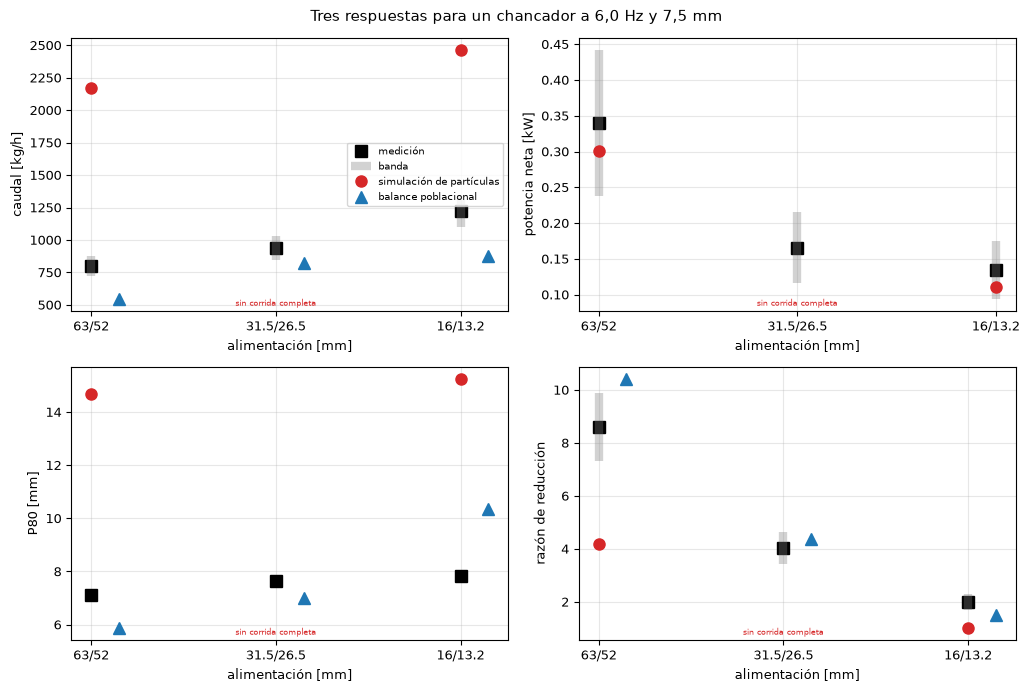

In [17]:
# Figura 1: los tres lados en las tres alimentaciones, con las bandas fijadas antes de las corridas y el error
# estándar de la simulación
x = np.arange(len(feeds))
fig, axes = plt.subplots(2, 2, figsize=(10.4, 7.0))
panels = (("throughput_kg_h", "caudal [kg/h]", bands["throughput_relative"]),
          ("net_power_kw", "potencia neta [kW]", bands["net_power_relative"]),
          ("p80_mm", "P80 [mm]", None),
          ("reduction_ratio", "razón de reducción", bands["reduction_ratio_relative"]))
for ax, (key, label, band) in zip(axes.ravel(), panels):
    raw = [points[fc]["measured"][key] for fc in feeds]
    meas = [v["value"] if isinstance(v, dict) else v for v in raw]
    sim = [points[fc]["simulation"][key] if points[fc]["simulation"]["status"] == "complete" else None for fc in feeds]
    ax.plot(x, meas, "ks", ms=8, label="medición")
    if band:
        low, high = [v * (1 - band) for v in meas], [v * (1 + band) for v in meas]
        ax.vlines(x, low, high, color="gray", lw=6, alpha=0.35, label="banda")
    have = [i for i, v in enumerate(sim) if v is not None]
    ax.plot(have, [sim[i] for i in have], "o", color="tab:red", ms=8, label="simulación de partículas")
    if key != "net_power_kw":
        ax.plot(x + 0.15, [points[fc]["population_balance"][key] for fc in feeds], "^", color="tab:blue", ms=8,
                label="balance poblacional")
    edge = ax.get_xaxis_transform()
    for i in (i for i, v in enumerate(sim) if v is None):
        ax.text(i, 0.02, "sin corrida completa", transform=edge, ha="center", fontsize=6, color="tab:red")
    ax.set_xticks(x)
    ax.set_xticklabels(feeds)
    ax.set_xlabel("alimentación [mm]")
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Tres respuestas para un chancador a 6,0 Hz y 7,5 mm")
fig.tight_layout()
plt.show()

Lectura de la figura 1. En caudal los marcadores de la simulación quedan muy sobre la banda gris de la medición en las dos alimentaciones que tienen corrida y los del balance quedan bajo ella en las tres. En potencia neta los marcadores de la simulación están dentro de la barra de 30 por ciento en ambas alimentaciones y no se grafica nada más; la alimentación intermedia no muestra marcador y lleva la etiqueta "sin corrida completa". En P80 los marcadores de la simulación están cerca de 15 mm frente a 7 a 8 medidos, y los del balance quedan entre 5,88 y 10,34 mm. En razón de reducción los marcadores del balance quedan más cerca de la barra en la alimentación intermedia, que es el veredicto cumplido. La figura no muestra el error estándar de las medias de la simulación, demasiado pequeño para dibujarlo a estas escalas, ni la dispersión del balance, que muestra la figura 3.

La figura 2 dibuja las curvas acumuladas de producto: la medida, la del balance y la de la simulación, donde existe una corrida de partículas.

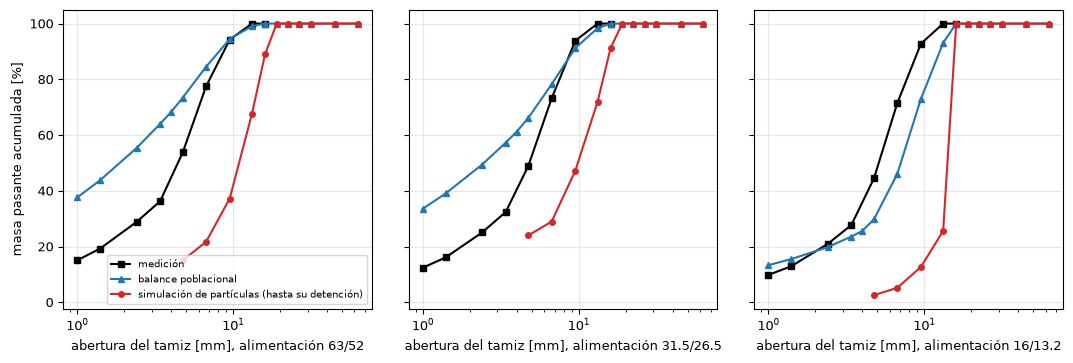

In [18]:
# Figura 2: la curva de producto de cada lado en cada alimentación: medida, balance poblacional y la corrida de
# partículas versionada
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.7), sharey=True)
for ax, fc in zip(axes, feeds):
    pt = points[fc]
    meas_curve, pb_curve = pt["measured"]["product"], pt["population_balance"]["product"]
    ax.plot(meas_curve["sieves_mm"], meas_curve["passing_pct"], "ks-", ms=4, label="medición")
    ax.plot(pb_curve["sieves_mm"], pb_curve["passing_pct"], "^-", color="tab:blue", ms=4, label="balance poblacional")
    sim_product = pt["simulation"]["product"]
    if sim_product:
        sizes = [s for s, v in zip(sim_product["sieves_mm"], sim_product["passing_pct"]) if v is not None]
        values = [v for v in sim_product["passing_pct"] if v is not None]
        ax.plot(sizes, values, "o-", color="tab:red", ms=4, label="simulación de partículas (hasta su detención)")
    ax.set_xscale("log")
    ax.set_xlabel(f"abertura del tamiz [mm], alimentación {fc}")
axes[0].set_ylabel("masa pasante acumulada [%]")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Lectura de la figura 2. Las curvas medidas llegan a 100 por ciento en los tamices de 13,2 a 16 mm en cada alimentación; las curvas de la simulación están desplazadas a la derecha de ellas en un factor de cerca de dos en tamaño en las dos alimentaciones con corrida, y su curva en la alimentación intermedia, que es el producto de la corrida hasta su detención y no un valor comparado, está desplazada también. Las curvas del balance quedan del lado fino de las medidas en la alimentación gruesa y la intermedia y del lado grueso en la fina; no las acotan. La figura no muestra lo que ocurre bajo 1 mm, donde terminan los marcadores del artículo, y los finos de la simulación bajo su esfera mínima de 4 mm se agrupan en un solo punto.

La última celda de esta sección lee la evidencia de por qué difieren los tres lados, del documento: el producto simulado frente al lado abierto y frente al tamaño máximo medido, y los términos del modelo de capacidad.

In [19]:
# La evidencia de por qué difieren, leída del documento: el producto simulado frente al lado abierto y al tamaño
# máximo medido
print("alim.  mayor [mm]  sobre el lado abierto  finos bajo 4 mm [%]  sim % bajo 13,2 mm  medido % bajo 13,2 mm")
for fc, pt in points.items():
    s, m = pt["simulation"], pt["measured"]["product"]
    sim_pass = "ausente"
    if s["product"]:
        sim_pass = f"{s['product']['passing_pct'][s['product']['sieves_mm'].index(13.2)]:.1f}"
    meas_pass = m["passing_pct"][m["sieves_mm"].index(13.2)]
    print(f"{fc:>10s} {s['largest_product_mm']:12.1f} {s['spheres_above_open_side']:20d}",
          f"{s['fines_below_minimum_pct']:20.1f} {sim_pass:>18s} {meas_pass:23.1f}")
print(f"lado abierto (lado cerrado más la carrera, leída como abertura inferior): {doc['settings']['oss_mm']} mm")
cap_doc = points["63/52"]["population_balance"]["capacity"]
shown = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in cap_doc.items()}
print("modelo de capacidad, alimentación gruesa:", shown)

alim.  mayor [mm]  sobre el lado abierto  finos bajo 4 mm [%]  sim % bajo 13,2 mm  medido % bajo 13,2 mm
     63/52         18.1                    9                 13.6               67.6                   100.0
 31.5/26.5         17.2                    0                 22.6               72.0                   100.0
   16/13.2         16.0                    0                  1.9               25.6                   100.0
lado abierto (lado cerrado más la carrera, leída como abertura inferior): 17.5 mm
modelo de capacidad, alimentación gruesa: {'depth_m': 0.2038, 'critical_speed_rpm': 396.01, 'regime': 'below_critical_speed', 'volumetric_m3_h': 1.0627, 'feed_factor': 0.5237, 'throw_factor': 0.364, 'material_factor': 1.0, 'density_t_m3': 2.7}


Por qué difieren, dicho solo desde lo que está registrado y sobre la implementación de `crushdem` (la simulación propia del artículo quedó a 5,9 por ciento de la potencia medida y a cerca de 11 por ciento del caudal medido; el artículo llama a esto "very good agreement" para la potencia (página 10) y dice que sus simulaciones "captured very well the trends" con el tamaño de alimentación (página 11)). El producto de la simulación es demasiado grueso: solo 67,6, 72,0 y 25,6 por ciento de él pasa 13,2 mm en las tres alimentaciones (el valor intermedio es el producto de la corrida hasta su detención), donde el producto medido está enteramente bajo ese tamaño, y sus esferas mayores son 18,1, 17,2 y 16,0 mm, con 9 esferas de la alimentación gruesa sobre el lado abierto de 17,5 mm. El registro de validación del paquete nombra siete causas candidatas y no prueba ninguna: el contacto de la Tabla 3, seis veces más blando que la esfera calibrada del propio artículo, que deja pasar por traslape esferas mayores que el lado abierto; la lectura de la carrera de 10 mm como abertura inferior, que da un lado abierto de 17,5 mm que el producto medido, enteramente bajo 13,2 mm, difícilmente concilia; la ley armónica del golpe y el ángulo de agarre de 20 grados, que el artículo no da; las placas planas y lisas; la ley de progenie frente al conjunto fijo de progenie del artículo; el efecto de tamaño extrapolado bajo 29 mm; y esferas enteras que pasan la abertura por su diámetro. El traslape es parte de la misma historia: 18 de los 29 golpes de la ventana de la alimentación gruesa y 17 de los 25 de la fina superan 0,3, así que las medias descansan en golpes donde el contacto ya está fuera de su supuesto.

El caudal del balance poblacional queda bajo la medición en 11,8 a 31,5 por ciento porque es la ecuación de Sastri sobre la geometría de la máquina con un factor de material de 1,0 que sus autores piden confirmar, y una alimentación de tres queda dentro del 20 por ciento que Sastri informa para sus propios datos. Su producto tampoco está ajustado: la clasificación es una primera estimación y los rangos de King para chancadores de cono, que se leen a continuación, acotan el P80 medido en las tres alimentaciones pero lo mueven en decenas de por ciento. No declara potencia porque la roca no tiene un índice de trabajo publicado, y el índice implícito no es constante entre alimentaciones. Ninguna de estas razones se probó cambiando el modelo y volviendo a correr; cada una es una lectura de lo que guarda el registro.

### Dónde cambia o se quiebra la comparación: las corridas que no se completaron, y los parámetros de clasificación

Dos cosas limitan lo que puede decir la comparación. La primera es que una corrida que se detiene no da veredicto. La alimentación 31,5/26,5 mm se detuvo en ambos peldaños de la escalera (el notebook 02 imprime los intentos), así que cinco de sus veredictos son no comparados con el fundamento `run_incomplete`, y el documento es `partial` por eso: ninguna frase de este notebook dice cómo le va a la simulación de partículas en la alimentación intermedia más allá del lote en vivo de 0,5 kg, que se completa, y el caudal de toda la corrida de tamaño completo detenida. Las corridas que sí se completaron lo hicieron solo en el segundo peldaño, con una gran parte de sus golpes sobre el primero, de modo que lo que dice la simulación en la alimentación gruesa y la fina descansa en un contacto fuera del supuesto de su modelo.

La segunda es la sensibilidad del balance a sus tres parámetros de clasificación, que toma de una primera estimación. La celda varía uno a la vez en el rango de King para chancadores de cono mientras los otros quedan en la primera estimación, e imprime el P80 en los dos extremos.

In [20]:
# Dónde se quiebra: el P80 del balance poblacional frente a cada uno de sus tres parámetros de clasificación, de a uno
grids = {"alpha1": np.linspace(0.5, 0.95, 8), "alpha2": np.linspace(1.7, 3.5, 8), "n": np.linspace(1.0, 3.0, 8)}
base = {"alpha1": 1.0, "alpha2": None, "n": labjaw.FIRST_ESTIMATE_K3}
sens = {}
for fc, pt in points.items():
    lo, hi = pt["feed_mm"]
    e50 = median_fracture_energy(labjaw.class_mean_mm(lo, hi) / 1000.0, ore)
    axb = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50)
    for name, grid in grids.items():
        p80s = []
        for value in grid:
            args = dict(base, **{name: float(value)})
            cls = labjaw.lab_classification(P.CSS_MM, P.THROW_MM, **args)
            p80s.append(labjaw.evaluate_lab_jaw(jaw, lo, hi, P.CSS_MM, P.SPEED_RPM, axb, classification=cls).p80_mm)
        sens[(fc, name)] = p80s
print("alim.  parámetro  P80 con su valor menor  con su valor mayor  cambio [%]")
for (fc, name), p80s in sens.items():
    print(f"{fc:>10s} {name:>10s} {p80s[0]:23.2f} {p80s[-1]:15.2f} {100 * (p80s[-1] - p80s[0]) / p80s[0]:+11.1f}")

alim.  parámetro  P80 con su valor menor  con su valor mayor  cambio [%]
     63/52     alpha1                    4.25            5.77       +35.8
     63/52     alpha2                    5.16            7.09       +37.5
     63/52          n                    6.89            5.62       -18.5
 31.5/26.5     alpha1                    5.09            6.83       +34.2
 31.5/26.5     alpha2                    6.06            9.34       +54.3
 31.5/26.5          n                    8.70            6.60       -24.1
   16/13.2     alpha1                    8.17           10.13       +24.0
   16/13.2     alpha2                    7.86           13.54       +72.2
   16/13.2          n                   13.48            9.49       -29.6


Cada parámetro mueve el P80 en decenas de por ciento en el rango de King para chancadores de cono; es una sensibilidad del modelo a rangos dados para chancadores de cono y no una incertidumbre publicada para un chancador de mandíbulas. En la alimentación gruesa, $K_1/\mathrm{CSS}$ de 0,5 a 0,95 lo sube de 4,25 a 5,77 mm (+35,8 por ciento), $K_2/\mathrm{CSS}$ de 1,7 a 3,5 de 5,16 a 7,09 (+37,5) y $K_3$ de 1 a 3 lo baja de 6,89 a 5,62 (-18,5). El efecto crece al afinarse la alimentación: $K_2/\mathrm{CSS}$ mueve el P80 de la alimentación fina en +72,2 por ciento, de 7,86 a 13,54 mm. Una primera estimación que no puede decir en qué punto de esos rangos está el chancador de laboratorio no puede esperarse que caiga dentro del 15 por ciento de la razón de reducción medida, y no cae salvo en una alimentación. La celda siguiente imprime la banda de las ocho esquinas del documento frente a los valores medidos.

In [21]:
# La banda de las ocho esquinas de los rangos de King, como la registra el documento, frente al P80 y la razón
# de reducción medidos
print("alim.  banda de P80 [mm]  medido  dentro  banda de la razón de reducción  medida  dentro")
for fc, pt in points.items():
    band, meas = pt["population_balance"]["band"], pt["measured"]
    lo_p, hi_p = band["p80_mm"]
    lo_r, hi_r = band["reduction_ratio"]
    inside_p = lo_p <= meas["p80_mm"] <= hi_p
    inside_r = lo_r <= meas["reduction_ratio"] <= hi_r
    print(f"{fc:>10s} {lo_p:6.2f} to {hi_p:6.2f} {meas['p80_mm']:9.2f} {str(inside_p):>7s}",
          f"{lo_r:9.2f} to {hi_r:6.2f} {meas['reduction_ratio']:10.2f} {str(inside_r):>7s}")

alim.  banda de P80 [mm]  medido  dentro  banda de la razón de reducción  medida  dentro
     63/52   3.32 to   8.91      7.12    True      6.88 to  18.46       8.60    True
 31.5/26.5   3.78 to  13.11      7.62    True      2.34 to   8.12       4.02    True
   16/13.2   5.32 to  14.43      7.83    True      1.08 to   2.92       1.99    True


La banda de las ocho esquinas contiene el P80 medido y la razón de reducción medida en las tres alimentaciones: 7,12 mm dentro de 3,32 a 8,91, 7,62 dentro de 3,78 a 13,11 y 7,83 dentro de 5,32 a 14,43, y las razones 8,60, 4,02 y 1,99 dentro de 6,88 a 18,46, 2,34 a 8,12 y 1,08 a 2,92. Es una afirmación más débil que el veredicto: el balance es consistente con la medición dentro de la dispersión de los rangos de King para chancadores de cono, que es una sensibilidad del modelo y no una incertidumbre publicada para un chancador de mandíbulas, y esa dispersión es lo bastante amplia, un factor de 2,7 del P80 menor al mayor en la alimentación gruesa, para contener casi cualquier producto. La figura 3 dibuja el P80 frente a cada parámetro.

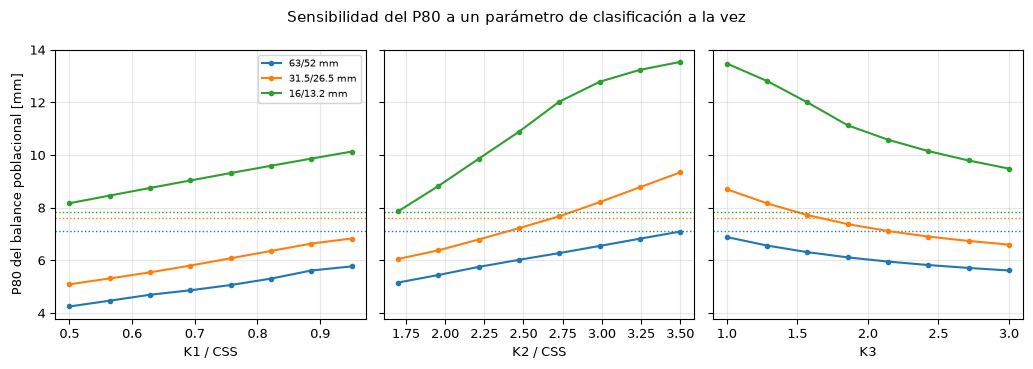

In [22]:
# Figura 3: el P80 del balance poblacional en el rango publicado de cada parámetro de clasificación; punteado: medido
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.7), sharey=True)
for ax, (name, grid) in zip(axes, grids.items()):
    for fc in feeds:
        line = ax.plot(grid, sens[(fc, name)], "o-", ms=3, label=f"{fc} mm")
        ax.axhline(points[fc]["measured"]["p80_mm"], color=line[0].get_color(), ls=":", lw=1)
    ax.set_xlabel({"alpha1": "K1 / CSS", "alpha2": "K2 / CSS", "n": "K3"}[name])
axes[0].set_ylabel("P80 del balance poblacional [mm]")
axes[0].legend(fontsize=7)
fig.suptitle("Sensibilidad del P80 a un parámetro de clasificación a la vez")
fig.tight_layout()
plt.show()

Lectura de la figura 3. Las curvas de las tres alimentaciones suben con $K_1/\mathrm{CSS}$ y $K_2/\mathrm{CSS}$ y bajan con $K_3$. El P80 medido de la alimentación intermedia, 7,62 mm, lo cruzan sus curvas frente a $K_2/\mathrm{CSS}$ y $K_3$, pero las curvas de la alimentación fina quedan sobre su P80 medido en todos los rangos (lo más cerca es 7,86 mm frente a 7,83 mm, con $K_2/\mathrm{CSS}$ = 1,7) y las de la alimentación gruesa quedan bajo el suyo (5,16 a 7,09 mm frente a 7,12 mm, lo más cerca con $K_2/\mathrm{CSS}$ = 3,5), así que ningún valor único de un parámetro pone al balance sobre la medición en las tres alimentaciones. La figura mueve un parámetro a la vez y no muestra las interacciones de los tres, que las ocho esquinas del documento sí cubren.

### Úsalo con tus propios datos

El lado del balance poblacional acepta cualquier chancador de laboratorio como un `LabJaw` (abertura, ancho, carrera, densidad, factor de material) y cualquier clase de alimentación estrecha, y `evaluate_lab_jaw` devuelve la capacidad, el producto, el P80, la razón de reducción, el término de Bond y las señales de las comprobaciones del motor; la roca entra como $A\,b$ desde `axb_from_fracture_energy`. La celda evalúa otro chancador de laboratorio, con las dimensiones del que informa Donovan (2003), una clase de alimentación de 45 a 31,5 mm, un lado cerrado de 7,94 mm y 300 golpes por minuto, con la roca del artículo en el lugar de la tuya.

El lado de partículas de otro punto es un nuevo punto de operación de la etapa, `pipeline.dem.points.Point`, corrido con el comando

```bash
python data-pipeline/run.py dem --runs <carpeta de los registros crudos> --output <carpeta>
```

que necesita el entorno de cálculo con `crushdem`, toma horas para un lote completo, guarda cada registro crudo bajo la carpeta, y escribe el documento y sus archivos de repetición bajo `<carpeta>/dem/`. Sin `--runs` los registros van bajo `<CAOS_DATA_ROOT>/chancadem/dem-runs`, la regla que muestra la segunda línea impresa. Una corrida que no se completa se registra tal como es. En la máquina del cálculo las tres alimentaciones tomaron cerca de 45 minutos (63/52 mm), 6 minutos (31,5/26,5 mm, que se detiene) y 70 minutos (16/13,2 mm).

In [23]:
# Su propio chancador: otra máquina de laboratorio y alimentación con el mismo módulo, y la regla de la etapa para
# sus corridas crudas
other = labjaw.LabJaw(gape_mm=95.3, width_mm=146.1, throw_mm=6.35, density_t_m3=2.65, material_k3=1.0)
e50_other = median_fracture_energy(0.0375, ore)
axb_other = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50_other)
mine = labjaw.evaluate_lab_jaw(other, 31.5, 45.0, 7.94, 300.0, axb_other)
print(f"capacidad {mine.throughput_kg_h:.0f} kg/h ({mine.capacity.branch}), P80 {mine.p80_mm:.2f} mm,",
      f"razón de reducción {mine.reduction_ratio:.2f}, cierre de masa {mine.mass_closure:.1e},",
      f"señales: {list(mine.flags)}")
folder = stage.runs_folder(None, {"CAOS_DATA_ROOT": "<data root>"})
print("carpeta de corridas crudas cuando CAOS_DATA_ROOT está definida:", folder.as_posix())
print("puntos de operación del cálculo:", [(pt.id, pt.feed_class, pt.capacity) for pt in P.POINTS])

capacidad 700 kg/h (low-speed), P80 6.73 mm, razón de reducción 6.41, cierre de masa 2.2e-16, señales: []
carpeta de corridas crudas cuando CAOS_DATA_ROOT está definida: <data root>/chancadem/dem-runs
puntos de operación del cálculo: [('63-52', '63/52', 1500), ('31.5-26.5', '31.5/26.5', 1500), ('16-13.2', '16/13.2', 3000)]


La capacidad del otro chancador es 700 kg/h en la rama de baja velocidad, con un P80 de 6,73 mm y una razón de reducción de 6,41; la masa cierra a 2,2e-16 y no se levanta ninguna señal del motor. Lo que hay que llevarse es lo que la salida no dice: este es el balance poblacional con la primera estimación del producto y la roca de otro artículo, una sensibilidad a una máquina distinta y no una predicción del ensayo de Donovan. La segunda línea muestra la regla de carpeta de la etapa y la tercera los tres puntos de operación del cálculo con sus casillas de partículas, 1500, 1500 y 3000.

## Resultados

**Respuesta:** En las tres alimentaciones el balance poblacional con un modelo de capacidad de mandíbulas es el lado más cercano a la medición, y la simulación de partículas que pierde es la de `crushdem` 0.6.0, no el método de elementos discretos tal como lo corrió el artículo: la simulación propia del artículo dio 0,32 kW frente a 0,34 kW medidos y cerca de 890 kg/h frente a 798,662 kg/h. El balance está más cerca en 9 de 9 pares de alimentación y magnitud (6 de 6 donde la simulación de partículas tiene una corrida completa), con caudales de 546,98, 826,17 y 876,65 kg/h frente a 798,7, 937,2 y 1220,4 medidos (errores de -31,5, -11,8 y -28,2 por ciento) mientras las corridas de 6 kg de `crushdem` pasan 2167 y 2464 kg/h en las dos alimentaciones que se completaron (+171 y +102 por ciento). Más cerca no es cumplido: de los 16 veredictos que se pudieron calcular, 13 están fuera de sus bandas, fijadas antes de las corridas, y solo 3 están dentro, los dos veredictos de potencia neta de la simulación y la razón de reducción del balance en la alimentación intermedia (+9,0 por ciento frente a 15). Los lotes en vivo de 0,5 kg en cada alimentación apuntan en el mismo sentido y no son valores comparados.

La potencia neta de la simulación, 0,3009 y 0,1108 kW frente a 0,34 y 0,1346 medidos, está dentro de su banda de 30 por ciento por una razón que no respalda al modelo: toma 500 y 162 J/kg frente a 1533 y 397 medidos mientras pasa el lote 2,7 y 2,0 veces demasiado rápido. Las razones están registradas y sin probar: para la simulación, un producto del doble de grueso que el medido, con esferas sobre el lado abierto, de un contacto más blando que la calibración del propio artículo y con 18 de 29 golpes de la ventana sobre el límite de traslape; para el balance, una ecuación de capacidad cuya propia comprobación con los datos de Hersam informa desviaciones menores que 20 por ciento en la mayoría de los casos, y una primera estimación de la clasificación cuya sensibilidad a los rangos de King para chancadores de cono mueve el P80 de 18 a 72 por ciento. La alimentación intermedia no tiene corrida de partículas completa a tamaño completo, y el documento lo dice con el estado `partial`.

## Resumen

- El modelo de capacidad de mandíbulas de Sastri (1994), calculado a mano para la alimentación gruesa, da 546,98 kg/h, igual al módulo del producto y 31,5 por ciento bajo los 798,7 kg/h medidos; sus tres caudales quedan de 11,8 a 31,5 por ciento bajo la medición.
- La clasificación del balance poblacional es una primera estimación con los rangos de King para chancadores de cono, usados por falta de valores para mandíbulas; la banda de las ocho esquinas contiene el P80 y la razón de reducción medidos en las tres alimentaciones, y cada parámetro mueve el P80 de 18 a 72 por ciento en su rango, una sensibilidad y no una incertidumbre publicada. La regla de energía del motor, escrita para el motor de cono, se aplica sin cambio.
- La energía medida implica un índice de trabajo de 3,08 a 5,45 kWh/t, no un valor único, así que el término de tamaño de Bond no da potencia; el balance no declara ninguna.
- La simulación de partículas de `crushdem` 0.6.0, corrida en vivo en lotes pequeños y leída a tamaño completo, pasa el lote 2,7 y 2,0 veces demasiado rápido con un producto cerca del doble de grueso, y sus dos veredictos de potencia cumplidos descansan en una energía por kilogramo 67 y 59 por ciento baja; la simulación propia del artículo quedó 5,9 por ciento bajo la potencia medida (0,32 frente a 0,34 kW, dentro de la banda de 30 por ciento) y cerca de 11 por ciento sobre el caudal medido según una lectura a ojo (cerca de 890 frente a 799 kg/h, justo fuera de la banda de 10 por ciento), y el artículo llama a esto "very good agreement" para la potencia (página 10) y dice que sus simulaciones "captured very well the trends" con el tamaño de alimentación (página 11).
- El balance poblacional está más cerca de la medición en todo par comparable pero cumple su banda en solo 1 de 6; de 27 veredictos, 13 no se cumplen, 3 se cumplen y 11 son no comparados.
- La alimentación intermedia no tiene corrida de partículas completa a tamaño completo: la comparación ahí es el balance frente a la medición.

## Referencias

- Austin, L. G., Klimpel, R. R., Luckie, P. T. (1984). Process engineering of size reduction: ball milling. SME-AIME. https://search.worldcat.org/title/11603131
- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Bond, F. C. (1952). The third theory of comminution. Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Donovan, J. G. (2003). Fracture toughness based models for the prediction of power consumption, product size, and capacity of jaw crushers. PhD thesis, Virginia Tech. https://vtechworks.lib.vt.edu/handle/10919/28544
- King, R. P. (2000). Technical Notes 5, Crushers. https://www.911metallurgist.com/wp-content/uploads/2017/04/Crushers.pdf
- Santibanez-Leal, F. (2026). crushdem 0.6.0, package page and README, with the validation record of the laboratory jaw. https://pypi.org/project/crushdem/
- Sastri, S. R. S. (1994). Capacities and performance characteristics of jaw crushers. Minerals and Metallurgical Processing, May 1994, 80-85. https://www.911metallurgist.com/wp-content/uploads/2016/02/Capacities-and-Sizing-of-jaw-crushers.pdf
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Whiten, W. J. (1972). The simulation of crushing plants with models developed using multiple spline regression. Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf